# TAREA 1: EVALUACIÓN DE LA PROBAILIDAD DE GANAR
Vamos a evaluar la probabilidad de ganar un partido a 5 sets en tenis en base a la probabilidad de ganar un punto normal y un punto crítico. Además, este problema será aplicado a otros deportes de raqueta como el badminton y el ping pong.
El caso de Roger Federer: En una entrevista, Federer indica que su porcentage de puntos ganados en toda su carrera es del 54%, lo cúal parece una cifra relativamente baja para un tenista de este calibre. Por otro lado, su porcentaje de partidos ganados es de un 80%. ¿Cómo es esto posible? 

## Transición de fase y el caso de Roger Federer

En este contexto, una **transición de fase** es una analogía: un cambio pequeño en la probabilidad de ganar cada punto puede producir un cambio mucho mayor en la probabilidad de ganar el partido. Esto ocurre porque los puntos se agrupan en juegos y sets, y basta con alcanzar ciertos resultados para ganar; por eso, todos los puntos no tienen el mismo efecto sobre el resultado final.

Esto ayuda a entender el caso de Federer: ganar alrededor del **54 % de los puntos** puede ser suficiente para ganar cerca del **80 % de los partidos**. No hace falta ganar la mayoría de los puntos por una diferencia grande; importa cómo esa pequeña ventaja se acumula a través de juegos y sets. Además, los puntos clave pueden influir mucho: ganar más de ellos aumenta las opciones de cerrar juegos y sets. La simulación explora este mecanismo, aunque no reproduce por sí sola las estadísticas reales de la carrera de Federer.

## 1. Evaluar porcentaje de victorias según porcentaje de puntos ganados
El porcentaje de ganar un punto normal se ha establecido en 0.5, mientras que el de ganar un punto clave o crítico es varibale. 

In [ ]:
# Simula partidos de tenis y cuenta cuántos puntos gana A.
import random
import numpy as np
import matplotlib.pyplot as plt

# Contadores usados para calcular el porcentaje real de puntos ganados por A.
PUNTOS_JUGADOS = 0
PUNTOS_GANADOS = 0

# En un punto normal, A gana según la probabilidad indicada.
def simular_punto(p_ganar_punto_A):
    return 'A' if random.random() < p_ganar_punto_A else 'B'

# En un punto clave se usa una probabilidad distinta, definida por separado.
def simular_punto_clave(p_ganar_punto_clave_A):
    return 'A' if random.random() < p_ganar_punto_clave_A else 'B'

# Juega un juego hasta que alguien gane por dos puntos de diferencia.
def simular_juego_normal(p_ganar_punto_A, p_ganar_clave_A):
    global PUNTOS_JUGADOS, PUNTOS_GANADOS
    puntos_A = 0
    puntos_B = 0
    while True:
        # Al llegar a 40 o a ventaja, los puntos se consideran clave.
        if (puntos_A >= 3 and puntos_A - puntos_B > 0) or (puntos_B >= 3 and puntos_B - puntos_A > 0) :
            if simular_punto_clave(p_ganar_clave_A) == 'A':
                puntos_A += 1
                PUNTOS_GANADOS += 1
            else:
                puntos_B += 1

        elif simular_punto(p_ganar_punto_A) == 'A':
            puntos_A += 1            
            PUNTOS_GANADOS += 1
        else:
            puntos_B += 1
        # Se registra cada punto jugado para calcular el porcentaje al final.
        PUNTOS_JUGADOS += 1        
            
        if puntos_A >= 4 and puntos_A - puntos_B >= 2:
            return 'A'
        elif puntos_B >= 4 and puntos_B - puntos_A >= 2:
            return 'B'

# Juega el desempate: se necesitan 7 puntos (o los indicados) y ganar por dos.
def simular_tiebreak(p_ganar_punto_A, p_ganar_clave_A, puntos_objetivo=7):
    global PUNTOS_JUGADOS, PUNTOS_GANADOS
    puntos_A = 0
    puntos_B = 0
    while True:
        # Los puntos a partir del objetivo también se tratan como puntos clave.
        if (puntos_A >= puntos_objetivo and puntos_A - puntos_B > 0) or (puntos_B >= puntos_objetivo and puntos_B - puntos_A > 0) :
            if simular_punto_clave(p_ganar_clave_A) == 'A':
                puntos_A += 1
                PUNTOS_GANADOS += 1
            else:
                puntos_B += 1

        elif simular_punto(p_ganar_punto_A) == 'A':
            puntos_A += 1
            PUNTOS_GANADOS += 1
        else:
            puntos_B += 1
        PUNTOS_JUGADOS += 1
            
        if puntos_A >= puntos_objetivo and puntos_A - puntos_B >= 2:
            return 'A'
        elif puntos_B >= puntos_objetivo and puntos_B - puntos_A >= 2:
            return 'B'

# Simula un set; al llegar a 6-6 se decide con un tie-break.
def simular_set(p_ganar_punto_A, p_ganar_clave_A, es_quinto_set=False):
    juegos_A = 0
    juegos_B = 0
    while True:
        if juegos_A == 6 and juegos_B == 6:
            # En el quinto set el desempate se juega a 10; en los demás, a 7.
            puntos_tb = 10 if es_quinto_set else 7
            return simular_tiebreak(p_ganar_punto_A, p_ganar_clave_A, puntos_objetivo=puntos_tb)
        
        ganador_juego = simular_juego_normal(p_ganar_punto_A, p_ganar_clave_A)
        if ganador_juego == 'A':
            juegos_A += 1
        else:
            juegos_B += 1
            
        if juegos_A >= 6 and juegos_A - juegos_B >= 2:
            return 'A'
        elif juegos_B >= 6 and juegos_B - juegos_A >= 2:
            return 'B'

# Simula un partido al mejor de cinco sets: gana quien consigue tres sets.
def simular_partido(prob_A, prob_clave_A):
    sets_A = 0
    sets_B = 0
    num_set = 1
    while sets_A < 3 and sets_B < 3:
        es_quinto = (num_set == 5)
        ganador_set = simular_set(prob_A, prob_clave_A, es_quinto_set=es_quinto)
        if ganador_set == 'A':
            sets_A += 1
        else:
            sets_B += 1
        num_set += 1
    return 'A' if sets_A == 3 else 'B'

# -------------------------------------------------------------
# SIMULACIÓN
# -------------------------------------------------------------
if __name__ == "__main__":
    # Se fija en 50% la probabilidad normal y se prueban distintas probabilidades clave.
    probs_punto = 0.5
    probs_punto_clave = np.linspace(0.25, 0.75, 26)
    
    # Para cada probabilidad clave se simulan muchos partidos y se estima el porcentaje de victorias.
    simulaciones_por_prob = 1500

    porcentajes_victoria = []
    pct_putnos_victoria_array = []

    print("Ejecutando simulación...")
    for p in probs_punto_clave:
        victorias = sum(1 for _ in range(simulaciones_por_prob) if simular_partido(probs_punto, p) == 'A')
        # Convierte el número de victorias en un porcentaje.
        pct = (victorias / simulaciones_por_prob) * 100
        porcentajes_victoria.append(pct)
        # pyrefly: ignore [division-by-zero]
        # Guarda el porcentaje de puntos ganados en los partidos de esta tanda.
        pct_putnos_victoria_array.append(PUNTOS_GANADOS/PUNTOS_JUGADOS * 100)        
        # pyrefly: ignore [division-by-zero]
        print(f"Prob. punto: {PUNTOS_GANADOS/PUNTOS_JUGADOS*100:.1f}% -> % Victorias partido: {pct:.1f}%")
        # Reinicia los contadores para medir la siguiente probabilidad clave por separado.
        PUNTOS_JUGADOS = 0
        PUNTOS_GANADOS = 0

    # Pasa las probabilidades clave a porcentaje para usarlas en el gráfico.
    prob_clave_pct = probs_punto_clave * 100

Ejecutando simulación...
Prob. punto: 42.5% -> % Victorias partido: 0.4%
Prob. punto: 43.0% -> % Victorias partido: 0.3%
Prob. punto: 43.7% -> % Victorias partido: 1.5%
Prob. punto: 44.3% -> % Victorias partido: 2.1%
Prob. punto: 45.1% -> % Victorias partido: 4.5%
Prob. punto: 45.6% -> % Victorias partido: 5.7%
Prob. punto: 46.2% -> % Victorias partido: 8.9%
Prob. punto: 46.9% -> % Victorias partido: 13.2%
Prob. punto: 47.5% -> % Victorias partido: 17.4%
Prob. punto: 48.0% -> % Victorias partido: 23.8%
Prob. punto: 48.5% -> % Victorias partido: 30.1%
Prob. punto: 49.2% -> % Victorias partido: 40.3%
Prob. punto: 49.6% -> % Victorias partido: 45.7%
Prob. punto: 50.2% -> % Victorias partido: 53.6%
Prob. punto: 50.8% -> % Victorias partido: 62.7%
Prob. punto: 51.4% -> % Victorias partido: 68.7%
Prob. punto: 52.1% -> % Victorias partido: 76.5%
Prob. punto: 52.8% -> % Victorias partido: 83.0%
Prob. punto: 53.1% -> % Victorias partido: 85.9%
Prob. punto: 53.8% -> % Victorias partido: 91.0%
Pr

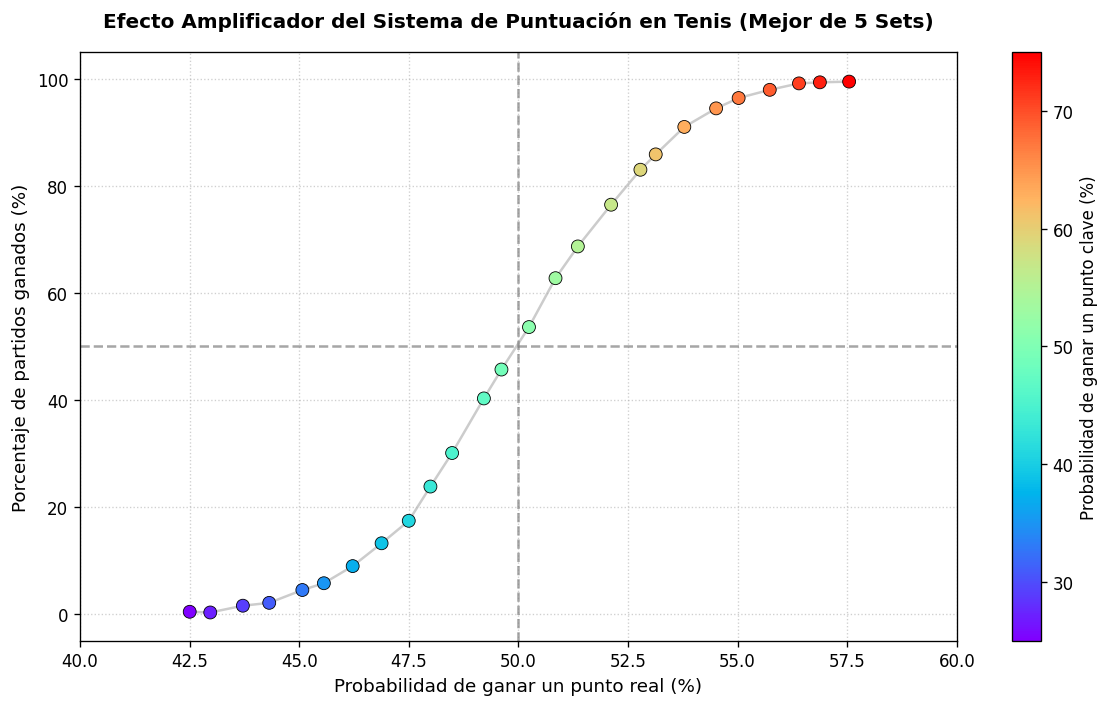

In [12]:
plt.figure(figsize=(10, 6), dpi=120)

    # Línea guía continua de fondo
plt.plot(pct_putnos_victoria_array, porcentajes_victoria, color='gray', linestyle='-', alpha=0.4, linewidth=1.5, zorder=1)

    # Puntos coloreados según la probabilidad de ganar un punto clave
scatter = plt.scatter(
        pct_putnos_victoria_array, 
        porcentajes_victoria, 
        c=prob_clave_pct,      # <--- Mapeo al % de punto clave
        cmap='rainbow', 
        s=60, 
        edgecolors='black', 
        linewidth=0.5,
        zorder=2
    )

    # Barra lateral indicando la probabilidad de punto clave
cbar = plt.colorbar(scatter)
cbar.set_label('Probabilidad de ganar un punto clave (%)', fontsize=10)

    # Líneas de referencia (50% punto / 50% partido)
plt.axvline(x=50, color='gray', linestyle='--', alpha=0.7)
plt.axhline(y=50, color='gray', linestyle='--', alpha=0.7)

plt.title('Efecto Amplificador del Sistema de Puntuación en Tenis (Mejor de 5 Sets)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Probabilidad de ganar un punto real (%)', fontsize=11)
plt.ylabel('Porcentaje de partidos ganados (%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(40, 60)
plt.ylim(-5, 105)
plt.tight_layout()
plt.savefig('simulacion_tenis_punto_clave_color.png')
plt.show()

## 2. Evaluar el porcentaje de victorias según porcentage de puntos normales y críticos ganados
El porcentage de puntos normales y puntos críticos ganados es variable.

In [14]:
import random
import seaborn as sns

# -------------------------------------------------------------
# EJECUCIÓN Y GENERACIÓN DE MATRIZ DE SIMULACIÓN
# -------------------------------------------------------------
if __name__ == "__main__":
    # Rango de probabilidades de 40% a 60%
    probs_normal = np.linspace(0.40, 0.60, 11)
    probs_clave = np.linspace(0.40, 0.60, 11)
    simulaciones_por_celda = 500

    matriz_victorias = np.zeros((len(probs_clave), len(probs_normal)))

    print("Ejecutando matriz de simulación...")
    for i, p_c in enumerate(probs_clave):
        for j, p_n in enumerate(probs_normal):
            victorias = sum(1 for _ in range(simulaciones_por_celda) if simular_partido(p_n, p_c) == 'A')
            matriz_victorias[i, j] = (victorias / simulaciones_por_celda) * 100

Ejecutando matriz de simulación...


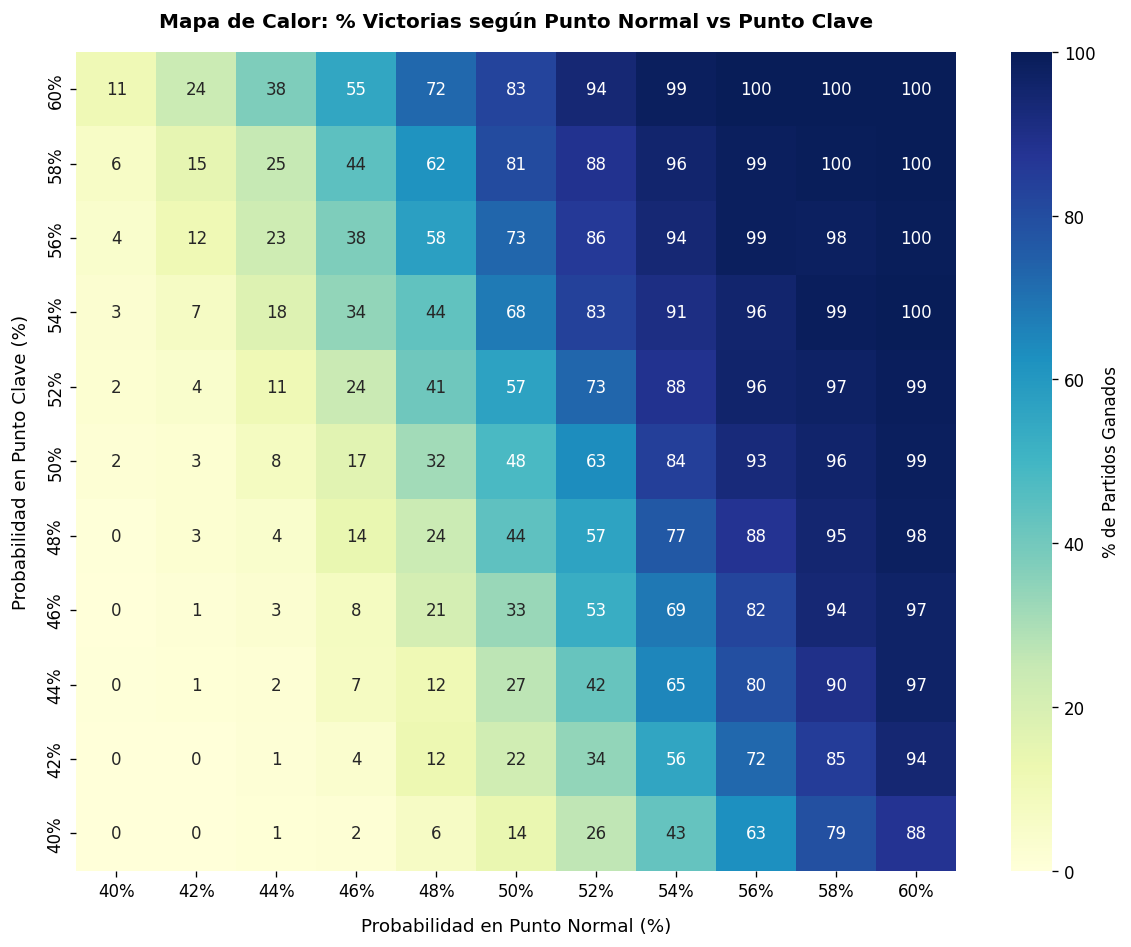

In [15]:
# 1. GENERACIÓN DEL MAPA DE CALOR
plt.figure(figsize=(10, 8), dpi=120)
sns.heatmap(
        matriz_victorias, 
        annot=True, 
        fmt=".0f", 
        cmap="YlGnBu", 
        xticklabels=[f"{p*100:.0f}%" for p in probs_normal],
        yticklabels=[f"{p*100:.0f}%" for p in probs_clave],
        cbar_kws={'label': '% de Partidos Ganados'}
    )

plt.title('Mapa de Calor: % Victorias según Punto Normal vs Punto Clave', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Probabilidad en Punto Normal (%)', fontsize=11, labelpad=10)
plt.ylabel('Probabilidad en Punto Clave (%)', fontsize=11, labelpad=10)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig('matriz_victorias_tenis_puntos_claves.png')
plt.show()

## 3. Evaluar el porcentage de victorias según probabilidad de ganar un punto (Tenis, bádminton y ping pong)

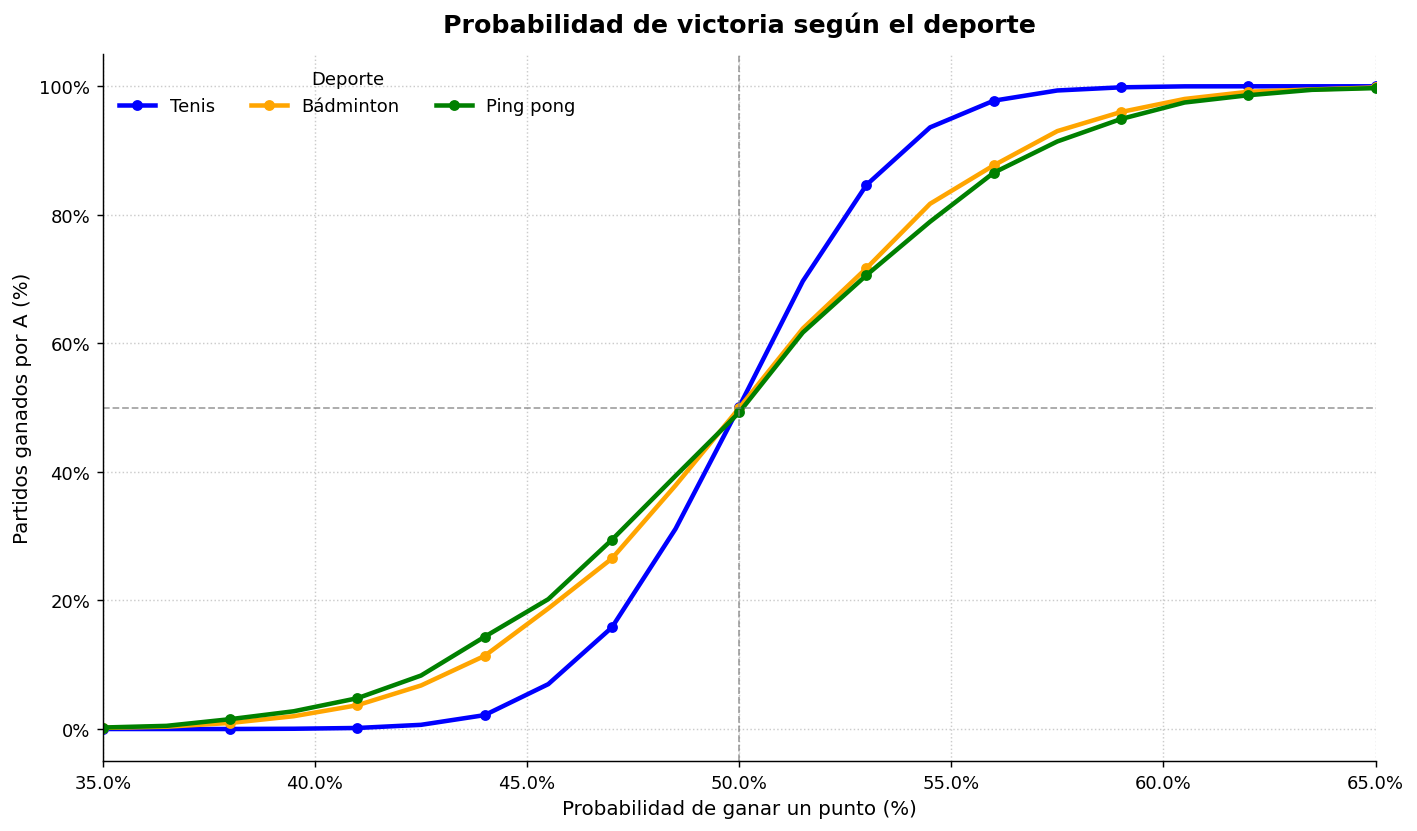

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Una semilla fija permite repetir la simulación y obtener los mismos resultados.
rng = np.random.default_rng(42)
NUM_PARTIDOS = 10_000
# Se prueban probabilidades del 35% al 65%, en pasos de 1.5 puntos porcentuales.
PROBABILIDADES = np.linspace(0.35, 0.65, 21)


def repartir_puntos(puntos_a, puntos_b, activos, probabilidad):
    """Juega un punto para cada partido que todavía sigue activo."""
    # Todos los puntos usan la misma probabilidad, sin importar el marcador.
    gana_a = (rng.random(puntos_a.size) < probabilidad) & activos
    puntos_a += gana_a
    puntos_b += activos & ~gana_a


def simular_juego_tenis(activos, probabilidad):
    """Simula juegos de tenis; se gana con al menos cuatro puntos y dos de ventaja."""
    puntos_a = np.zeros(activos.size, dtype=int)
    puntos_b = np.zeros(activos.size, dtype=int)

    while True:
        gana_a = (puntos_a >= 4) & (puntos_a - puntos_b >= 2)
        gana_b = (puntos_b >= 4) & (puntos_b - puntos_a >= 2)
        jugando = activos & ~(gana_a | gana_b)
        if not np.any(jugando):
            return gana_a

        repartir_puntos(puntos_a, puntos_b, jugando, probabilidad)


def simular_tiebreak(activos, objetivo, probabilidad):
    """Simula un tie-break: llegar al objetivo y ganar por dos puntos."""
    puntos_a = np.zeros(activos.size, dtype=int)
    puntos_b = np.zeros(activos.size, dtype=int)

    while True:
        gana_a = (puntos_a >= objetivo) & (puntos_a - puntos_b >= 2)
        gana_b = (puntos_b >= objetivo) & (puntos_b - puntos_a >= 2)
        jugando = activos & ~(gana_a | gana_b)
        if not np.any(jugando):
            return gana_a

        repartir_puntos(puntos_a, puntos_b, jugando, probabilidad)


def simular_set_tenis(activos, es_quinto_set, probabilidad):
    """Simula un set de tenis y el tie-break cuando el marcador llega a 6-6."""
    juegos_a = np.zeros(activos.size, dtype=int)
    juegos_b = np.zeros(activos.size, dtype=int)

    while True:
        # Un set se gana con seis juegos y dos de ventaja; 7-6 indica tie-break ganado.
        gana_a = ((juegos_a >= 6) & (juegos_a - juegos_b >= 2)) | ((juegos_a == 7) & (juegos_b == 6))
        gana_b = ((juegos_b >= 6) & (juegos_b - juegos_a >= 2)) | ((juegos_b == 7) & (juegos_a == 6))
        pendientes = activos & ~(gana_a | gana_b)
        if not np.any(pendientes):
            return gana_a

        # Los partidos 6-6 juegan tie-break; los demás continúan con un juego normal.
        en_tiebreak = pendientes & (juegos_a == 6) & (juegos_b == 6)
        en_juego = pendientes & ~en_tiebreak
        ganador_juego = simular_juego_tenis(en_juego, probabilidad)
        juegos_a += en_juego & ganador_juego
        juegos_b += en_juego & ~ganador_juego

        if np.any(en_tiebreak):
            # En esta simulación, el tie-break del quinto set se juega a 10 y los otros a 7.
            objetivo = np.where(es_quinto_set, 10, 7)
            ganador_tiebreak = simular_tiebreak(en_tiebreak, objetivo, probabilidad)
            juegos_a += en_tiebreak & ganador_tiebreak
            juegos_b += en_tiebreak & ~ganador_tiebreak


def simular_partidos_tenis(probabilidad, cantidad):
    """Simula partidos de tenis al mejor de cinco sets."""
    sets_a = np.zeros(cantidad, dtype=int)
    sets_b = np.zeros(cantidad, dtype=int)

    while True:
        # Gana el partido quien obtiene tres sets; los partidos ya decididos se dejan inactivos.
        activos = (sets_a < 3) & (sets_b < 3)
        if not np.any(activos):
            return sets_a >= 3

        es_quinto_set = (sets_a + sets_b) == 4
        ganador_set = simular_set_tenis(activos, es_quinto_set, probabilidad)
        sets_a += activos & ganador_set
        sets_b += activos & ~ganador_set


def simular_set_por_puntos(activos, objetivo, probabilidad):
    """Simula un set de bádminton o ping pong, ganado por puntos y con dos de ventaja."""
    puntos_a = np.zeros(activos.size, dtype=int)
    puntos_b = np.zeros(activos.size, dtype=int)

    while True:
        gana_a = (puntos_a >= objetivo) & (puntos_a - puntos_b >= 2)
        gana_b = (puntos_b >= objetivo) & (puntos_b - puntos_a >= 2)
        jugando = activos & ~(gana_a | gana_b)
        if not np.any(jugando):
            return gana_a

        repartir_puntos(puntos_a, puntos_b, jugando, probabilidad)


def simular_partidos_por_sets(probabilidad, cantidad, puntos_set, sets_necesarios):
    """Simula partidos donde cada set se gana alcanzando una cantidad de puntos."""
    sets_a = np.zeros(cantidad, dtype=int)
    sets_b = np.zeros(cantidad, dtype=int)

    while True:
        # Solo siguen activos los partidos en los que nadie ha ganado todavía.
        activos = (sets_a < sets_necesarios) & (sets_b < sets_necesarios)
        if not np.any(activos):
            return sets_a >= sets_necesarios

        ganador_set = simular_set_por_puntos(activos, puntos_set, probabilidad)
        sets_a += activos & ganador_set
        sets_b += activos & ~ganador_set


# Se guarda el resultado de cada probabilidad para dibujar una curva por deporte.
resultados = {"Tenis": [], "Bádminton": [], "Ping pong": []}

for probabilidad in PROBABILIDADES:
    # NumPy procesa 10.000 partidos a la vez, reduciendo el tiempo de simulación.
    victorias_tenis = simular_partidos_tenis(probabilidad, NUM_PARTIDOS)
    # Bádminton: al mejor de tres sets a 21 puntos.
    victorias_badminton = simular_partidos_por_sets(
        probabilidad, NUM_PARTIDOS, puntos_set=21, sets_necesarios=2
    )
    # Ping pong: al mejor de cinco sets, a 11 puntos.
    victorias_ping_pong = simular_partidos_por_sets(
        probabilidad, NUM_PARTIDOS, puntos_set=11, sets_necesarios=3
    )

    # El promedio de valores True es la fracción de partidos ganados; se convierte a porcentaje.
    resultados["Tenis"].append(np.mean(victorias_tenis) * 100)
    resultados["Bádminton"].append(np.mean(victorias_badminton) * 100)
    resultados["Ping pong"].append(np.mean(victorias_ping_pong) * 100)

# Gráfico comparativo: eje X = probabilidad por punto; eje Y = porcentaje de victorias.
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=130)
ax.plot(PROBABILIDADES * 100, resultados["Tenis"], color="blue", label="Tenis", linewidth=2.5, marker="o", markevery=2, markersize=5)
ax.plot(PROBABILIDADES * 100, resultados["Bádminton"], color="orange", label="Bádminton", linewidth=2.5, marker="o", markevery=2, markersize=5)
ax.plot(PROBABILIDADES * 100, resultados["Ping pong"], color="green", label="Ping pong", linewidth=2.5, marker="o", markevery=2, markersize=5)

# Las líneas de referencia muestran el caso neutral: 50% de probabilidad y 50% de victorias.
ax.axvline(50, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.axhline(50, color="gray", linestyle="--", linewidth=1, alpha=0.7)
ax.set_xlabel("Probabilidad de ganar un punto (%)", fontsize=11)
ax.set_ylabel("Partidos ganados por A (%)", fontsize=11)
ax.set_title("Probabilidad de victoria según el deporte", fontsize=14, fontweight="bold", pad=12)
ax.set_xlim(35, 65)
# Se deja un margen visual por debajo de 0% y por encima de 100%.
ax.set_ylim(-5, 105)
ax.set_xticks(np.arange(35, 66, 5))
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(True, linestyle=":", linewidth=0.8, alpha=0.65)
ax.legend(title="Deporte", frameon=False, ncol=3, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## Interpretación de los resultados

El eje horizontal muestra la probabilidad de que el jugador A gane **cada punto**; el eje vertical indica qué porcentaje de los 10.000 partidos simulados ganó A. Cuando la probabilidad por punto está cerca del 50%, los resultados de los tres deportes también rondan el 50% de victorias. Las pequeñas diferencias se deben al azar de la simulación.

Al aumentar la probabilidad por punto, también aumenta la probabilidad de ganar el partido; al disminuirla, ocurre lo contrario. En esta simulación, la curva del tenis es más pronunciada: una ventaja pequeña por punto se acumula primero en juegos y luego en sets. Las curvas de bádminton y ping pong reflejan sus propios formatos de sets, por lo que la relación entre puntos ganados y partidos ganados no es idéntica.

## Conclusión general

El resultado final depende no solo de cuántos puntos se ganan, sino también de cómo se agrupan esos puntos para decidir juegos, sets y partidos. Por eso, una ventaja moderada en cada punto puede traducirse en una ventaja mayor en partidos, y el efecto depende del sistema de puntuación de cada deporte. Esta es una simulación simplificada: usa la misma probabilidad para todos los puntos y no representa todas las condiciones de partidos reales.